# Homework08

Exercises to practice pandas, data analysis and classification

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different classification models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework08/raw/main/Homework08_utils.pyc" -O Homework08_utils.pyc

!wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/0801-500.tar.gz | tar xz

In [2]:
import pandas as pd
import PIL.Image as PImage

from os import listdir, path

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from data_utils import classification_error, display_confusion_matrix, regression_error

from image_utils import get_pixels, make_image

from Homework08_utils import CamUtils

## Classification

The dataset we are going to use has images from $25$ different security cameras, and our task is to separate them by camera. Some of the cameras move, some of them don't, and there are more than $1000$ images, so there's no way we want to do this by hand.

### Loading Data

If we look at the images in `./data/image/0801-500/train/`, we'll notice that they are named and organized in a very particular way. They're all in the same directory and the first part of their filename specifies which camera they came from. Even though those `ids` are numbers, they're not sequential, so we'll use some helper functions to extract a unique `label` from their filenames.

This is exactly what the `OrdinalEncoder` class does, but since we only have to encode this one column, we'll do it by hand while we read the files in.

Alternatively, we could try using a `OneHotEncoder`, but since we have $25$ cameras, adding $25$ sparse columns to our dataset might confuse our classification fitting.

In [3]:
# this creates a list of all the files in a given directory, that end in .jpg
train_files = [f for f in listdir("./data/image/0801-500/train") if f.endswith(".jpg")]

In [4]:
# TODO: check and see what is inside the list here
print(len(train_files))
print(train_files[:10])

250
['24-24.jpg', '28-77.jpg', '19-20.jpg', '26-60.jpg', '10-49.jpg', '25-83.jpg', '28-67.jpg', '05-40.jpg', '28-69.jpg', '03-23.jpg']


In [5]:
# sorted view by number-- previous was random
print(sorted(train_files)[:10])

['01-07.jpg', '01-17.jpg', '01-19.jpg', '01-30.jpg', '01-32.jpg', '01-33.jpg', '01-38.jpg', '01-39.jpg', '01-40.jpg', '01-46.jpg']


Now we'll read the image pixels and extract their labels. `CamUtils.get_label()` is the helper function we'll use to "encode" and return a label id based on the filename.

In [6]:
pixel_data = []
label_data = []

for fname in train_files:
  label = CamUtils.get_label(fname)
  img = PImage.open(path.join("./data/image/0801-500/train", fname))
  pixel_data.append(get_pixels(img))
  label_data.append(label)

In [7]:
# TODO: check if labels got extracted correctly by looking at 
#       the first few items of the label list and the filename list

print(train_files[:10])
print(label_data[:10])

['24-24.jpg', '28-77.jpg', '19-20.jpg', '26-60.jpg', '10-49.jpg', '25-83.jpg', '28-67.jpg', '05-40.jpg', '28-69.jpg', '03-23.jpg']
[19, 23, 15, 21, 8, 20, 23, 3, 23, 2]


The labels and the filenames won't match exactly since labels start at $0$ and the filenames start at $01$ and skip some numbers.

We can open some images from pixels, just to make sure we loaded them correctly (they're squares, so no need to specify `width`):

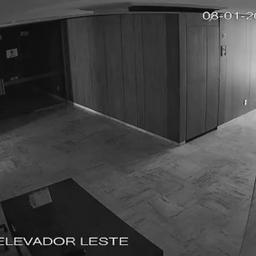

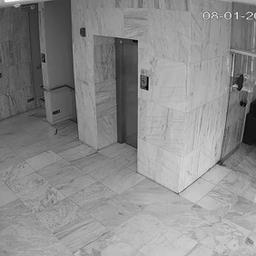

In [8]:
display(make_image(pixel_data[0]))
display(make_image(pixel_data[10]))

And now might not be a bad time to peek into the `data/image/0801-500/` directories to see what's inside them and what the images look like.... and get to know the data...

### DataFrame it

Let's put our raw pixel data into a `DataFrame`, and create a column for storing each image's label.

(this next cell might take a while to run)

In [9]:
train_df = pd.DataFrame(pixel_data)
train_df["label"] = label_data

Let's inspect our `DataFrame`:

In [10]:
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,65527,65528,65529,65530,65531,65532,65533,65534,65535,label
0,71,71,71,71,71,71,71,71,70,70,...,75,75,75,76,77,77,78,79,79,19
1,121,121,121,121,121,121,121,121,124,124,...,158,154,153,149,143,143,147,148,145,23
2,55,59,50,58,62,58,68,61,64,64,...,80,72,78,84,87,85,82,80,80,15
3,96,96,96,97,97,98,98,98,98,98,...,108,106,104,103,103,104,104,104,103,21
4,64,59,62,55,87,93,51,66,65,65,...,247,250,249,248,248,247,246,245,245,8


In [11]:
# quick check
print(train_df.shape)                 
print(train_df.isna().sum().sum())       
print(train_df.drop(columns="label").min().min(), train_df.drop(columns="label").max().max())

(250, 65537)
0
0 255


### Insight

<span style="color:hotpink">
Does anything stand out as peculiar about the feature values in our <code>DataFrame</code>?<br>
Do we have to encode or scale our data?<br>
Why? Or, why not?<br>
</span>

<span style="color:hotpink;">

### Does anything stand out?

There are 65,537 columns: 65,536 pixel values (a 256 × 256 image) plus the label. That is a pretty large number of features, especially compared to 250 images. Each pixel is a single number, not an `(r, g, b)` tuple, but since the images are grayscale, it is not really surprising that each pixel is one value. The label column is a number too, but it’s a camera ID, so it is a quantity/value that stays constant.

### Do we have to encode or scale?

I would think that no more encoding is needed, as the features are already numeric, and the camera IDs were already turned into labels 0 to 24 by `CamUtils.get_label()`.

For scale, I would also think that it is not really needed, as all features are pixel brightness values on the same 0 to 255 scale, so no feature dominates the others because we grayscale the images. It is different compared to the audio data from HW06, where some frequency bins were in the millions and others were near zero.

Scaling could be tried anyway, but I wouldn’t expect a big difference.
</span>

### Test Files

If that worked, repeat the process for the test files inside the `./data/image/0801-500/test/` directory.

We can almost use the exact same steps as we did above to create a `DataFrame`, the only difference being that we don't have labels for these images.

In [13]:
# TODO: create a list of files in the test/ directory
test_files = [f for f in listdir("./data/image/0801-500/test") if f.endswith(".jpg")]

# TODO: check its length and content
print(len(test_files))
print(sorted(test_files)[:10])

test_pixel_data = []

# TODO: loop over files and load their pixels into a list
for fname in test_files:
  img = PImage.open(path.join("./data/image/0801-500/test", fname))
  test_pixel_data.append(get_pixels(img))

# TODO: load into DataFrame (this might take 20 - 30 seconds)
test_df = pd.DataFrame(test_pixel_data)

print(test_df.shape)        
print(test_df.isna().sum().sum())

1573
['10032152.jpg', '10033240.jpg', '10034975.jpg', '10040056.jpg', '10046825.jpg', '10074475.jpg', '10086325.jpg', '10098175.jpg', '10110025.jpg', '10165325.jpg']
(1573, 65536)
0


Check the `DataFrame`

In [14]:
test_df.head()

,0,1,2,3,4,5,6,7,8,9,...,65526,65527,65528,65529,65530,65531,65532,65533,65534,65535
0,119,119,119,120,120,121,121,121,121,121,...,125,120,121,121,121,121,120,119,118,117
1,173,172,164,168,203,246,255,237,249,253,...,173,181,175,168,160,166,175,165,157,165
2,170,170,170,170,170,170,170,170,171,171,...,133,122,111,107,101,96,93,92,94,96
3,43,45,46,45,43,42,43,44,41,42,...,124,133,132,126,120,119,123,125,123,119
4,65,63,66,72,78,85,103,120,99,96,...,69,67,63,65,66,67,68,67,66,65


Looks like data!!

We could train a `RandomForestClassifier` directly on this `DataFrame` and see what would happen, but my guess is that Python runs out of memory and crashes our tab/browser/computer...

We'll use _projection_ to reduce the number of dimensions in our dataset. Projection is when we just drop some of the columns in our dataset. 

Which columns ? That's up to us.

Let's first try using the first $N$ columns/features where $N$ is a number around $10$.

This is how we get the first $N$ columns from a `DataFrame`:

In [15]:
# split input and output features
NUM_FEATURES = 10
chosen_columns = train_df.columns[:NUM_FEATURES]
train_features = train_df[chosen_columns]

out_features = train_df["label"]

# also separate test dataset features
test_features = test_df[chosen_columns]

In [16]:
# check/print
print(train_features.shape)  
print(test_features.shape)  
print(out_features.shape)   
print(list(chosen_columns))  

(250, 10)
(1573, 10)
(250,)
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


From our [Week 08](https://github.com/PSAM-5020-2026F-A/WK08) notebook, we can create a classification model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (not needed! done! ⚡️)
3. Normalize the data (not needed! done! 🍾)
4. Separate the outcome variable and the input features (done! ☀️)
5. Create a model using chosen features
6. Run model on training data and measure error*
7. Run model on test data, measure error*, plot predictions, interpret results

We could use the same `regression_error()` function we used previously to measure the error of our classifier model, but this could lead to $2$ issues. First, we don't have labels for the images in the test dataset, and second, the regression error reported might be higher than it actually is because an image with label $0$ that gets mislabeled as $5$ will count as being more wrong than if it was mislabeled $2$. And we don't want that. We just want to get the percentage of classifications that our model gets correctly.

To simplify calculating the classification accuracy we can use the `CamUtils.classification_accuracy()` function. This function takes $2$ parameters, a list of files and a list of predictions. It will work with the test and train datasets and will calculate a more meaningful accuracy value than the one returned by `regression_error()`.

In [17]:
# TODO: create a brand new classifier
model = RandomForestClassifier(random_state=1010) #used from the wine exercises

# TODO: fit the model
model.fit(train_features, out_features)

# TODO: run predictions
train_predictions = model.predict(train_features)
test_predictions = model.predict(test_features)

# TODO: measure classification accuracy
CamUtils.classification_accuracy(train_files, train_predictions)

print("train:", CamUtils.classification_accuracy(train_files, train_predictions))
print("test:", CamUtils.classification_accuracy(test_files, test_predictions))



train: 1.0
test: 0.6522568340750159


That should look promising. Let's run this on our test dataset.

Remember we already separated the test data features into a variable called `test_features` above.

Now we just have to run the prediction and measure accuracy.

In [18]:
# TODO: run predictions on test data
# TODO: measure classification accuracy
test_predictions = model.predict(test_features)
print(CamUtils.classification_accuracy(test_files, test_predictions))

0.6522568340750159


### Interpretation

Using just the first $10$ pixels of the image the classifier is able to label most of the images correctly.

<span style="color:hotpink">
How can we improve this classifier? How does the number of features affect the classification accuracy of the test data?<br>
How does the choice of pixels affect the accuracy?<br><br>
If you're curious, repeat the modeling above, but using the <code>SVC</code> classifier instead of <code>RandomForest</code>.<br>How does the choice of modeling technique affect the accuracy?<br><br>
Experiment with some of these parameters and explain your findings below.
</span>

<span style="color:hotpink;">

### Number of features

Test accuracy increased when I added more pixels: 0.37 with 1, 0.60 with 5, 0.65 with 10, 0.78 with 50, 0.84 with 100, and 0.91 with 500. It started to level out after that, as the model with 1,000 features scored 0.908. Training accuracy was already 1.0 with 10 features, so the extra pixels helped the model generalize instead of just memorize the training data.

### Modeling technique

SVC performed much worse than RandomForest using the same 10 features. SVC could not even fit the training data well, suggesting that it was underfitting. With default settings and unscaled pixel values, SVC may struggle to distinguish between 25 cameras using only 10 features. Scaling the data or using more features might help, but I did not test that.

### Choice of pixels

Using 100 pixels per image, the top of the image scored 0.844, the middle scored 0.868, and the bottom scored 0.860. The middle and bottom performed slightly better, but the difference was only about two percentage points.

### How to improve

- Use more features: Increasing the number of pixels to around 500 improved performance, although adding more features beyond that did not help.
- Sample pixels across the whole image: This could capture more distinguishing characteristics of each camera.
- Collect more training images: There are only 250 images for 25 cameras, so adding more training examples could help the model generalize better.
- Try scaling for SVC: Scaling the pixel values and testing different SVC settings could help improve its performance.


</span>

In [19]:
# number of features
for n in [1, 5, 10, 50, 100, 500, 1000]:
  cols = train_df.columns[:n]

  model_n = RandomForestClassifier(random_state=1010)
  model_n.fit(train_df[cols], out_features)

  train_acc = CamUtils.classification_accuracy(train_files, model_n.predict(train_df[cols]))
  test_acc = CamUtils.classification_accuracy(test_files, model_n.predict(test_df[cols]))
  print(n, "features -> train:", round(train_acc, 3), "test:", round(test_acc, 3))

1 features -> train: 0.708 test: 0.374
5 features -> train: 0.988 test: 0.599
10 features -> train: 1.0 test: 0.652
50 features -> train: 1.0 test: 0.776
100 features -> train: 1.0 test: 0.844
500 features -> train: 1.0 test: 0.907
1000 features -> train: 1.0 test: 0.908


In [21]:
# svc instead of RandomForest
model_svc = SVC()
model_svc.fit(train_features, out_features)

print("train:", CamUtils.classification_accuracy(train_files, model_svc.predict(train_features)))
print("test:", CamUtils.classification_accuracy(test_files, model_svc.predict(test_features)))

train: 0.444
test: 0.4259376986649714


In [ ]:
# choice of pixels
# choose 100 pixels from three different places in the image
first_cols = train_df.columns[:100]        # top of the image
middle_cols = train_df.columns[32000:32100]  # middle of the image
last_cols = train_df.columns[65000:65100]    # bottom of the image

for name, cols in [("first", first_cols), ("middle", middle_cols), ("last", last_cols)]:
  model_p = RandomForestClassifier(random_state=1010)
  model_p.fit(train_df[cols], out_features)
  test_acc = CamUtils.classification_accuracy(test_files, model_p.predict(test_df[cols]))
  print(name, "-> test:", round(test_acc, 3))

first -> test: 0.844
middle -> test: 0.868
last -> test: 0.86


: 